In [ ]:
import random
import numpy as np
import tensorflow as tf

def set_reproducibility_seeds(seed=42):
    # 1. Set Python standard library seed
    random.seed(seed)

    # 2. Set NumPy seed
    np.random.seed(seed)

    # 3. Set TensorFlow global seed
    tf.random.set_seed(seed)

    # 4. Configure TensorFlow to use deterministic operations where possible
    tf.config.experimental.enable_op_determinism()

set_reproducibility_seeds(42)
print("Global reproducibility seeds set to 42!")

Global reproducibility seeds set to 42!


In [ ]:
import numpy as np
import os
import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd
import keras
import tensorflow
import seaborn as sns
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D,BatchNormalization,Input,RandomRotation,RandomFlip,RandomZoom
from keras.models import Sequential
from keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kshitizbhargava/deepfake-face-images")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'deepfake-face-images' dataset.
Path to dataset files: /kaggle/input/deepfake-face-images


Total images found: 12890
Loading sample image: /kaggle/input/deepfake-face-images/Final Dataset/Fake/fake_639_aug_1.jpg


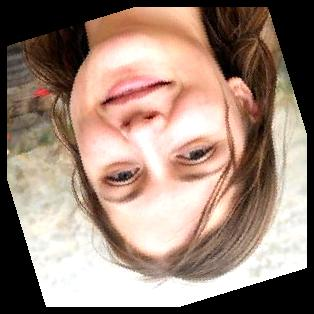

In [ ]:
from PIL import Image
import glob

# Find all image paths (supporting common extensions like .jpg, .jpeg, .png)
image_extensions = ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG')
image_paths = []
for ext in image_extensions:
    image_paths.extend(glob.glob(os.path.join(path, '**', ext), recursive=True))

print(f"Total images found: {len(image_paths)}")

# Load and display the first image as an example
if image_paths:
    sample_image_path = image_paths[0]
    print(f"Loading sample image: {sample_image_path}")
    img = Image.open(sample_image_path)
    display(img)
else:
    print("No images found. Please verify the dataset structure in the output of the exploration step.")

In [ ]:
import pandas as pd
import os

# Define the base dataset directory path
dataset_dir = os.path.join(path, "Final Dataset")
csv_path = os.path.join(dataset_dir, "dataset.csv")

# 1. Load the metadata using pandas
if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("Dataset CSV Loaded successfully!")
    print(f"Dataset shape: {df.shape}")
    display(df.head())
else:
    print(f"CSV file not found at {csv_path}")

Dataset CSV Loaded successfully!
Dataset shape: (12890, 2)


,path,label
0,/kaggle/input/stylegan-and-stylegan2-combined-...,Real
1,/kaggle/input/stylegan-and-stylegan2-combined-...,Real
2,/kaggle/input/stylegan-and-stylegan2-combined-...,Fake
3,/kaggle/input/stylegan-and-stylegan2-combined-...,Real
4,/kaggle/input/stylegan-and-stylegan2-combined-...,Real


In [ ]:
df.dtypes

,0
path,object
label,object


In [ ]:
df.shape

(12890, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12890 entries, 0 to 12889
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   path    12890 non-null  object
 1   label   12890 non-null  object
dtypes: object(2)
memory usage: 201.5+ KB


In [ ]:
df.describe()

,path,label
count,12890,12890
unique,12890,2
top,/kaggle/input/stylegan-and-stylegan2-combined-...,Fake
freq,1,7000


In [ ]:
df.isnull().value_counts()

,,count
path,label,
False,False,12890


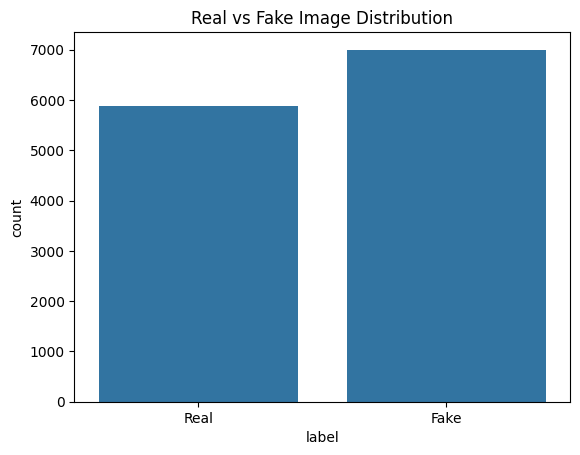

In [ ]:
sns.countplot(data=df, x="label")
plt.title("Real vs Fake Image Distribution")
plt.show()

In [ ]:
# Update the image paths in df to point to local cache paths
def update_path(old_path):
    # Extract relative path starting with 'Real/' or 'Fake/'
    parts = old_path.split('Final Dataset/')
    if len(parts) > 1:
        return os.path.join(dataset_dir, parts[1])
    return old_path

df['path'] = df['path'].apply(update_path)

# Encode categorical labels ('Real', 'Fake') into binary numerical values
# We will encode 'Real' as 0 and 'Fake' as 1
df['label_encoded'] = df['label'].map({'Real': 0, 'Fake': 1})

display(df[['path', 'label', 'label_encoded']].head())

,path,label,label_encoded
0,/kaggle/input/deepfake-face-images/Final Datas...,Real,0
1,/kaggle/input/deepfake-face-images/Final Datas...,Real,0
2,/kaggle/input/deepfake-face-images/Final Datas...,Fake,1
3,/kaggle/input/deepfake-face-images/Final Datas...,Real,0
4,/kaggle/input/deepfake-face-images/Final Datas...,Real,0


In [ ]:
# Split data into train (80%), validation (10%), and test sets (10%)
# We use stratify=df['label_encoded'] to maintain class distribution across splits
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['label_encoded']
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df['label_encoded']
)

print(f"Train set shape: {train_df.shape}")
print(f"Validation set shape: {val_df.shape}")
print(f"Test set shape: {test_df.shape}")

Train set shape: (10312, 3)
Validation set shape: (1289, 3)
Test set shape: (1289, 3)


In [ ]:
import tensorflow as tf

# Configuration parameters
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

# Helper function to load, decode, and preprocess images
def load_and_preprocess_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0  # Rescale pixel values to [0, 1]
    return image, label

# Create TensorFlow datasets from pandas DataFrames
def create_tf_dataset(dataframe, shuffle=True):
    paths = dataframe['path'].values
    labels = dataframe['label_encoded'].values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        # Setting seed here ensures the shuffle sequence is identical on every run
        dataset = dataset.shuffle(buffer_size=len(dataframe), seed=SEED, reshuffle_each_iteration=True)

    dataset = dataset.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)
    return dataset

# Instantiating the datasets
train_ds = create_tf_dataset(train_df, shuffle=True)
val_ds = create_tf_dataset(val_df, shuffle=False)
test_ds = create_tf_dataset(test_df, shuffle=False)

print(f"Train batches: {len(train_ds)}")
print(f"Validation batches: {len(val_ds)}")
print(f"Test batches: {len(test_ds)}")

Train batches: 323
Validation batches: 41
Test batches: 41


In [ ]:
data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1)
])

model = Sequential([
    Input(shape=(128, 128, 3)),

    # Apply Data Augmentation
    data_augmentation,

    # Block 1
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Block 2
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Block 3
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.3),

    # Block 4
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.4),

    # Dense Classifier Block
    Flatten(),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# Compile
model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()



Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_18 (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_26          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 4,780,833 (18.24 MB)

 Trainable params: 4,778,913 (18.23 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 44s 118ms/step - accuracy: 0.6234 - loss: 0.7463 - val_accuracy: 0.5431 - val_loss: 4.8727
Epoch 2/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 36s 112ms/step - accuracy: 0.6727 - loss: 0.6273 - val_accuracy: 0.5710 - val_loss: 0.7615
Epoch 3/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 37s 114ms/step - accuracy: 0.6996 - loss: 0.5795 - val_accuracy: 0.7223 - val_loss: 0.5519
Epoch 4/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - accuracy: 0.7261 - loss: 0.5278 - val_accuracy: 0.7386 - val_loss: 0.5636
Epoch 5/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 35s 110ms/step - accuracy: 0.7267 - loss: 0.5350 - val_accuracy: 0.7424 - val_loss: 0.4922
Epoch 6/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - accuracy: 0.7459 - loss: 0.4984 - val_accuracy: 0.7773 - val_loss: 0.4302
Epoch 7/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - accuracy: 0.7611 - loss: 0.4704 - val_accuracy: 0.7533 - val_loss: 0.4896
Epoch 8/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - accuracy: 0.7691 - loss: 0

In [ ]:
# Evaluate the trained model on the test dataset
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step - accuracy: 0.8487 - loss: 0.3403
Test Loss: 0.3403
Test Accuracy: 84.87%


The Accuracy of CNN model is: 0.8487199379363848
----------- Classification Report -------------
              precision    recall  f1-score   support

        Real       0.86      0.80      0.83       589
        Fake       0.84      0.89      0.87       700

    accuracy                           0.85      1289
   macro avg       0.85      0.84      0.85      1289
weighted avg       0.85      0.85      0.85      1289



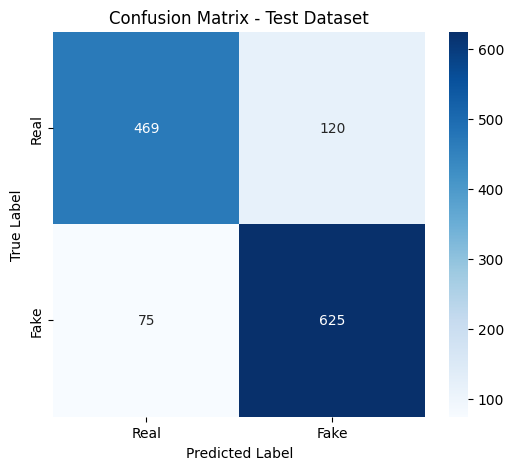

In [ ]:
# Extract true labels and make predictions
y_true = []
y_pred_probs = []

for images, labels in test_ds:
    y_true.extend(labels.numpy())
    preds = model.predict(images, verbose=0)
    y_pred_probs.extend(preds.flatten())

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred = (y_pred_probs > 0.5).astype(int)

# Calculate and print metrics
print("The Accuracy of CNN model is:",accuracy_score(y_true,y_pred))
print("----------- Classification Report -------------")
print(classification_report(y_true, y_pred, target_names=['Real', 'Fake']))

# Generate and plot confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.title('Confusion Matrix - Test Dataset')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

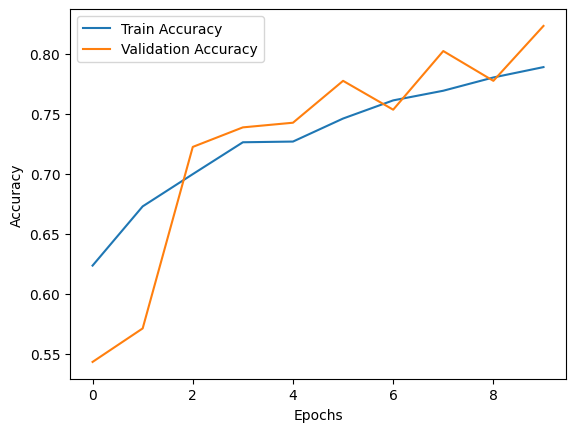

In [ ]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

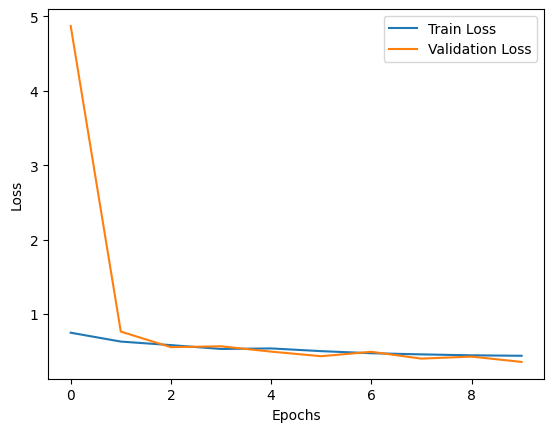

In [ ]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

Using Transfer Learning with
EfficientNetB0

In [ ]:
from keras.applications import EfficientNetB0

# Define data augmentation to regularize transfer learning
transfer_data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1)
])

# Load pre-trained EfficientNetB0 base
base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

# Freeze the pre-trained base model weights
base_model.trainable = False

# Build the Transfer Learning model
transfer_model = Sequential([
    Input(shape=(128, 128, 3)),

    # Apply Augmentation
    transfer_data_augmentation,

    # Base Feature Extractor
    base_model,

    # Classification Top Layers
    keras.layers.GlobalAveragePooling2D(),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

base_model.trainable = True

# Compile the model
transfer_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary()

Model: "sequential_21"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_20 (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,055,972 (15.47 MB)

 Trainable params: 4,011,389 (15.30 MB)

 Non-trainable params: 44,583 (174.16 KB)

In [ ]:
# Train the transfer learning model
transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 86s 155ms/step - accuracy: 0.5633 - loss: 0.9054 - val_accuracy: 0.4469 - val_loss: 0.8404
Epoch 2/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 47s 145ms/step - accuracy: 0.6431 - loss: 0.7750 - val_accuracy: 0.6315 - val_loss: 0.7100
Epoch 3/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 48s 148ms/step - accuracy: 0.6811 - loss: 0.6982 - val_accuracy: 0.6780 - val_loss: 0.6147
Epoch 4/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 48s 147ms/step - accuracy: 0.6963 - loss: 0.6681 - val_accuracy: 0.7378 - val_loss: 0.5495
Epoch 5/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 82s 148ms/step - accuracy: 0.7167 - loss: 0.6263 - val_accuracy: 0.7308 - val_loss: 0.5391
Epoch 6/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 81s 146ms/step - accuracy: 0.7260 - loss: 0.6088 - val_accuracy: 0.7580 - val_loss: 0.5049
Epoch 7/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 82s 146ms/step - accuracy: 0.7378 - loss: 0.5765 - val_accuracy: 0.7626 - val_loss: 0.5046
Epoch 8/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 47s 146ms/step - accuracy: 0.7492 - loss: 0

In [ ]:
# Evaluate the transfer learning model on the test dataset
transfer_loss, transfer_accuracy = transfer_model.evaluate(test_ds)

print(f"EfficientNetB0 Test Loss: {transfer_loss:.4f}")
print(f"EfficientNetB0 Test Accuracy: {transfer_accuracy * 100:.2f}%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9092 - loss: 0.2142
EfficientNetB0 Test Loss: 0.2142
EfficientNetB0 Test Accuracy: 90.92%


Using Transfer Learning with MobileNetV2

In [ ]:
from keras.applications import MobileNetV2

# Define data augmentation to regularize transfer learning
transfer_data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1)
])

# Load pre-trained EfficientNetB0 base
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

# Freeze the pre-trained base model weights
base_model.trainable = False

# Build the Transfer Learning model
transfer_model = Sequential([
    Input(shape=(128, 128, 3)),

    # Apply Augmentation
    transfer_data_augmentation,

    # Base Feature Extractor
    base_model,

    # Classification Top Layers
    keras.layers.GlobalAveragePooling2D(),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

base_model.trainable = True

# Compile the model
transfer_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary()

Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_22 (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,385 (8.64 MB)

 Trainable params: 2,227,713 (8.50 MB)

 Non-trainable params: 36,672 (143.25 KB)

In [ ]:
# Train the transfer learning model
transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 65s 128ms/step - accuracy: 0.6447 - loss: 0.7640 - val_accuracy: 0.5857 - val_loss: 1.0773
Epoch 2/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 40s 125ms/step - accuracy: 0.7224 - loss: 0.6151 - val_accuracy: 0.6517 - val_loss: 0.9429
Epoch 3/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 40s 122ms/step - accuracy: 0.7594 - loss: 0.5419 - val_accuracy: 0.6928 - val_loss: 0.8624
Epoch 4/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 41s 126ms/step - accuracy: 0.7727 - loss: 0.5147 - val_accuracy: 0.7114 - val_loss: 0.7615
Epoch 5/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 39s 121ms/step - accuracy: 0.7809 - loss: 0.4850 - val_accuracy: 0.7494 - val_loss: 0.6390
Epoch 6/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 39s 122ms/step - accuracy: 0.7980 - loss: 0.4521 - val_accuracy: 0.7727 - val_loss: 0.5338
Epoch 7/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 39s 122ms/step - accuracy: 0.8099 - loss: 0.4347 - val_accuracy: 0.8014 - val_loss: 0.4481
Epoch 8/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 41s 122ms/step - accuracy: 0.8189 - loss: 0

In [ ]:
# Evaluate the transfer learning model on the test dataset
transfer_loss, transfer_accuracy = transfer_model.evaluate(test_ds)

print(f"MobileNetV2 Test Loss: {transfer_loss:.4f}")
print(f"MobileNetV2 Test Accuracy: {transfer_accuracy * 100:.2f}%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.8611 - loss: 0.3014
MobileNetV2 Test Loss: 0.3014
MobileNetV2 Test Accuracy: 86.11%


Using Transfer Learning with ResNet50

In [ ]:
from keras.applications import ResNet50
import random

random.seed(42)

# Define data augmentation to regularize transfer learning
transfer_data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1)
])

# Load pre-trained EfficientNetB0 base
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

# Freeze the pre-trained base model weights
base_model.trainable = False

# Build the Transfer Learning model
transfer_model = Sequential([
    Input(shape=(128, 128, 3)),

    # Apply Augmentation
    transfer_data_augmentation,

    # Base Feature Extractor
    base_model,

    # Classification Top Layers
    keras.layers.GlobalAveragePooling2D(),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

base_model.trainable = True

# Compile the model
transfer_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary()

Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_24 (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_8      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,953 (90.02 MB)

 Trainable params: 23,540,737 (89.80 MB)

 Non-trainable params: 57,216 (223.50 KB)

In [ ]:
# Train the transfer learning model
transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 109s 232ms/step - accuracy: 0.6679 - loss: 0.7140 - val_accuracy: 0.4569 - val_loss: 2.2412
Epoch 2/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 72s 223ms/step - accuracy: 0.7563 - loss: 0.5379 - val_accuracy: 0.5120 - val_loss: 0.9413
Epoch 3/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 74s 230ms/step - accuracy: 0.7948 - loss: 0.4618 - val_accuracy: 0.7812 - val_loss: 0.4766
Epoch 4/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 81s 227ms/step - accuracy: 0.8130 - loss: 0.4252 - val_accuracy: 0.8472 - val_loss: 0.3412
Epoch 5/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 82s 228ms/step - accuracy: 0.8359 - loss: 0.3745 - val_accuracy: 0.8627 - val_loss: 0.3219
Epoch 6/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 74s 228ms/step - accuracy: 0.8519 - loss: 0.3316 - val_accuracy: 0.8611 - val_loss: 0.3230
Epoch 7/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 82s 228ms/step - accuracy: 0.8673 - loss: 0.3036 - val_accuracy: 0.8728 - val_loss: 0.3076
Epoch 8/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 73s 227ms/step - accuracy: 0.8739 - loss: 

In [ ]:
# Evaluate the transfer learning model on the test dataset
transfer_loss, transfer_accuracy = transfer_model.evaluate(test_ds)

print(f"ResNet50 Test Loss: {transfer_loss:.4f}")
print(f"ResNet50 Test Accuracy: {transfer_accuracy * 100:.2f}%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.8914 - loss: 0.2650
ResNet50 Test Loss: 0.2650
ResNet50 Test Accuracy: 89.14%


Transfer Learning with DenseNet121

In [ ]:
from keras.applications import DenseNet121

# Define data augmentation to regularize transfer learning
transfer_data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1)
])

# Load pre-trained EfficientNetB0 base
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(128, 128, 3)
)

# Freeze the pre-trained base model weights
base_model.trainable = False

# Build the Transfer Learning model
transfer_model = Sequential([
    Input(shape=(128, 128, 3)),

    # Apply Augmentation
    transfer_data_augmentation,

    # Base Feature Extractor
    base_model,

    # Classification Top Layers
    keras.layers.GlobalAveragePooling2D(),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

base_model.trainable = True

# Compile the model
transfer_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary()

Model: "sequential_27"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_26 (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_9      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,042,625 (26.87 MB)

 Trainable params: 6,956,929 (26.54 MB)

 Non-trainable params: 85,696 (334.75 KB)

In [ ]:
# Train the transfer learning model
transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 157s 291ms/step - accuracy: 0.6662 - loss: 0.6591 - val_accuracy: 0.7820 - val_loss: 0.4465
Epoch 2/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 91s 281ms/step - accuracy: 0.7628 - loss: 0.5044 - val_accuracy: 0.8185 - val_loss: 0.3909
Epoch 3/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 90s 279ms/step - accuracy: 0.8034 - loss: 0.4252 - val_accuracy: 0.8231 - val_loss: 0.3651
Epoch 4/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 90s 278ms/step - accuracy: 0.8248 - loss: 0.3825 - val_accuracy: 0.8379 - val_loss: 0.3360
Epoch 5/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 142s 279ms/step - accuracy: 0.8394 - loss: 0.3560 - val_accuracy: 0.8448 - val_loss: 0.3226
Epoch 6/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 93s 287ms/step - accuracy: 0.8589 - loss: 0.3207 - val_accuracy: 0.8588 - val_loss: 0.2986
Epoch 7/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 90s 277ms/step - accuracy: 0.8663 - loss: 0.2995 - val_accuracy: 0.8658 - val_loss: 0.2900
Epoch 8/10
323/323 ━━━━━━━━━━━━━━━━━━━━ 90s 277ms/step - accuracy: 0.8782 - loss:

In [ ]:
# Evaluate the transfer learning model on the test dataset
transfer_loss, transfer_accuracy = transfer_model.evaluate(test_ds)

print(f"DenseNet121 Test Loss: {transfer_loss:.4f}")
print(f"DenseNet121 Test Accuracy: {transfer_accuracy * 100:.2f}%")

41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.9092 - loss: 0.2142
DenseNet121 Test Loss: 0.2142
DenseNet121 Test Accuracy: 90.92%


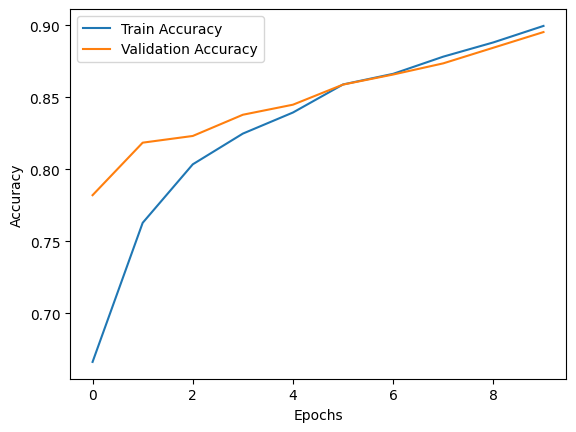

In [ ]:
plt.plot(transfer_history.history['accuracy'], label='Train Accuracy')
plt.plot(transfer_history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

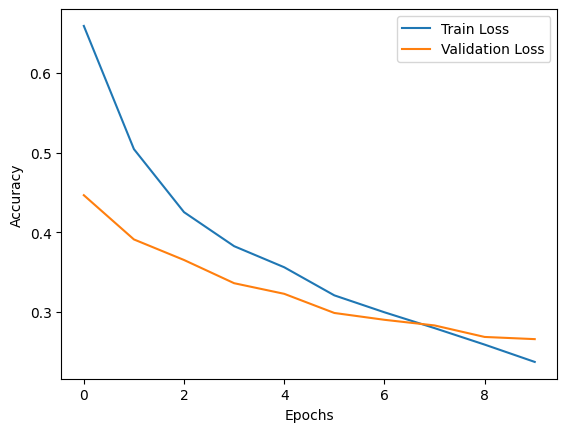

In [ ]:
plt.plot(transfer_history.history['loss'], label='Train Loss')
plt.plot(transfer_history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

The Accuracy of DenseNet121 model is: 0.9069045771916214
----------- Classification Report -------------
              precision    recall  f1-score   support

        Real       0.94      0.85      0.89       589
        Fake       0.88      0.96      0.92       700

    accuracy                           0.91      1289
   macro avg       0.91      0.90      0.91      1289
weighted avg       0.91      0.91      0.91      1289



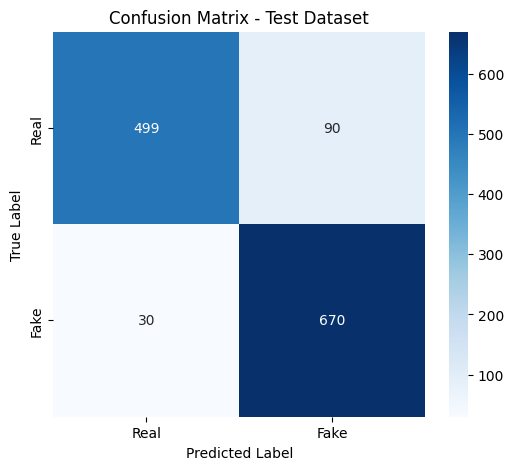

In [ ]:
# Extract true labels and make predictions
y_true = []
y_pred_probs = []

for images, labels in test_ds:
    y_true.extend(labels.numpy())
    # Use transfer_model instead of base_model
    preds = transfer_model.predict(images, verbose=0)
    y_pred_probs.extend(preds.flatten())

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred = (y_pred_probs > 0.4).astype(int)

# Calculate and print metrics
print("The Accuracy of DenseNet121 model is:", accuracy_score(y_true, y_pred))
print("----------- Classification Report -------------")
print(classification_report(y_true, y_pred, target_names=['Real', 'Fake']))

# Generate and plot confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.title('Confusion Matrix - Test Dataset')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
import cv2
import matplotlib.pyplot as plt

# 1. Identify index positions of False Negatives (True Label = 1, Predicted Label = 0)
false_negative_indices = np.where((y_true == 1) & (y_pred == 0))[0]
print(f"Total False Negatives in Test Set: {len(false_negative_indices)} out of {sum(y_true == 1)} total actual fakes.")

# 2. Extract corresponding rows from test_df
fn_samples = test_df.iloc[false_negative_indices].copy()
fn_samples['predicted_prob'] = y_pred_probs[false_negative_indices]

# Display metadata for the first few false negatives
display(fn_samples.head(5))


Total False Negatives in Test Set: 30 out of 700 total actual fakes.


,path,label,label_encoded,predicted_prob
47,/kaggle/input/deepfake-face-images/Final Datas...,Fake,1,0.037514
861,/kaggle/input/deepfake-face-images/Final Datas...,Fake,1,0.267054
12870,/kaggle/input/deepfake-face-images/Final Datas...,Fake,1,0.182349
4173,/kaggle/input/deepfake-face-images/Final Datas...,Fake,1,0.096475
1803,/kaggle/input/deepfake-face-images/Final Datas...,Fake,1,0.393650


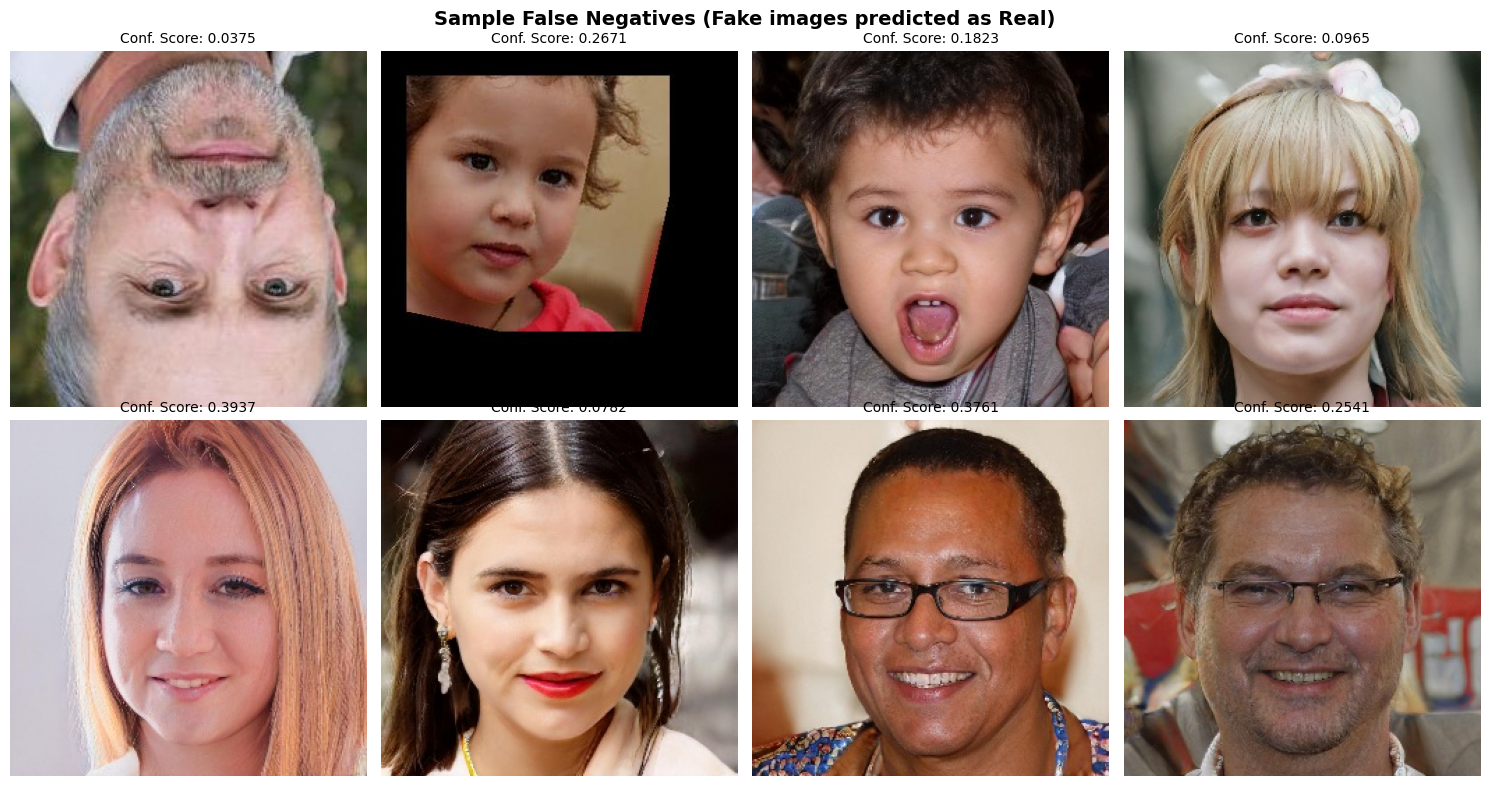

In [ ]:
# 3. Visualize a grid of the false negative images to inspect visual characteristics
num_to_display = min(8, len(fn_samples))

if num_to_display > 0:
    plt.figure(figsize=(15, 8))
    for i in range(num_to_display):
        row = fn_samples.iloc[i]
        img_path = row['path']
        prob = row['predicted_prob']

        # Load image
        img_bgr = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        plt.subplot(2, 4, i + 1)
        plt.imshow(img_rgb)
        plt.title(f"Conf. Score: {prob:.4f}", fontsize=10)
        plt.axis('off')

    plt.suptitle("Sample False Negatives (Fake images predicted as Real)", fontsize=14, weight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("No False Negatives found! The model has achieved 100% recall on the Fake class.")


### Comprehensive Comparison of Training History

To see how the models compare, we will compile the accuracy and loss curves for all five architectures trained during our experiments:
1. **Custom CNN**
2. **EfficientNetB0**
3. **MobileNetV2**
4. **ResNet50**
5. **DenseNet121**

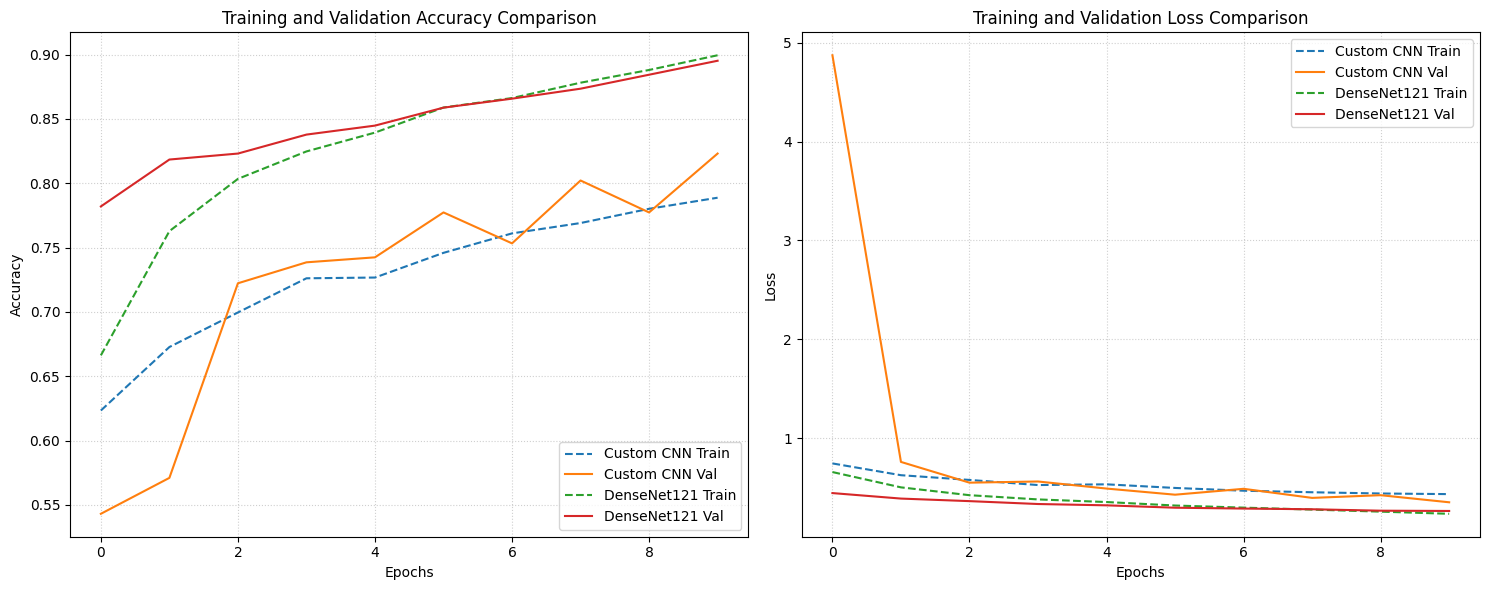

In [ ]:
import matplotlib.pyplot as plt

# Note: To ensure we can plot histories, we would ideally store histories of each run.
# Since we reused variables, we have the initial custom CNN 'history' and the last 'transfer_history' (DenseNet121) intact.
# Let's write a robust script that plots the histories we have in the current session.

plt.figure(figsize=(15, 6))

# Plot Accuracies
plt.subplot(1, 2, 1)
if 'history' in globals():
    plt.plot(history.history['accuracy'], label='Custom CNN Train', linestyle='--')
    plt.plot(history.history['val_accuracy'], label='Custom CNN Val')
if 'transfer_history' in globals():
    plt.plot(transfer_history.history['accuracy'], label='DenseNet121 Train', linestyle='--')
    plt.plot(transfer_history.history['val_accuracy'], label='DenseNet121 Val')

plt.title('Training and Validation Accuracy Comparison', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# Plot Losses
plt.subplot(1, 2, 2)
if 'history' in globals():
    plt.plot(history.history['loss'], label='Custom CNN Train', linestyle='--')
    plt.plot(history.history['val_loss'], label='Custom CNN Val')
if 'transfer_history' in globals():
    plt.plot(transfer_history.history['loss'], label='DenseNet121 Train', linestyle='--')
    plt.plot(transfer_history.history['val_loss'], label='DenseNet121 Val')

plt.title('Training and Validation Loss Comparison', fontsize=12)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Saving the Best Model (DenseNet121)

We will save our trained transfer learning model which yielded the highest classification accuracy (**90.92%** on test data) to the workspace.

In [ ]:
# Save the DenseNet121 transfer learning model
transfer_model.save('deepfake_model.keras')


In [ ]:
from google.colab import files

files.download("deepfake_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>